In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import Model, layers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.datasets import cifar10

# Reproducible experiment settings
tf.keras.utils.set_random_seed(42)
IMAGE_SIZE = 96
BATCH_SIZE = 32
EPOCHS = 20
CLASS_NAMES = ["airplane", "automobile", "truck"]
CLASS_IDS = [0, 1, 9]

In [2]:
# Load CIFAR-10 and keep only airplane, automobile, and truck.
(x_train_all, y_train_all), (x_test, y_test) = cifar10.load_data()
y_train_all = y_train_all.ravel()
y_test = y_test.ravel()

train_mask = np.isin(y_train_all, CLASS_IDS)
test_mask = np.isin(y_test, CLASS_IDS)
x_train_all = x_train_all[train_mask]
y_train_all = y_train_all[train_mask]
x_test = x_test[test_mask]
y_test = y_test[test_mask]

# Change labels 0, 1, 9 into labels 0, 1, 2.
y_train_all = np.where(y_train_all == 0, 0, np.where(y_train_all == 1, 1, 2))
y_test = np.where(y_test == 0, 0, np.where(y_test == 1, 1, 2))

x_train, x_val, y_train, y_val = train_test_split(
    x_train_all,
    y_train_all,
    test_size=0.2,
    random_state=42,
    stratify=y_train_all
)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2417s 14us/step


In [3]:
train_dataset = tf.data.Dataset.from_tensor_slices((x_train, y_train))
train_dataset = train_dataset.shuffle(len(x_train), seed=42).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

validation_dataset = tf.data.Dataset.from_tensor_slices((x_val, y_val))
validation_dataset = validation_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((x_test, y_test))
test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Training samples:", len(x_train))
print("Validation samples:", len(x_val))
print("Test samples:", len(x_test))
print("Classes:", CLASS_NAMES)

Training samples: 12000
Validation samples: 3000
Test samples: 3000
Classes: ['airplane', 'automobile', 'truck']


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - accuracy: 0.8869 - loss: 0.3619 - val_accuracy: 0.9473 - val_loss: 0.1690 - learning_rate: 1.0000e-05
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - accuracy: 0.9490 - loss: 0.1368 - val_accuracy: 0.9567 - val_loss: 0.1253 - learning_rate: 1.0000e-05
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 111ms/step - accuracy: 0.9662 - loss: 0.0865 - val_accuracy: 0.9627 - val_loss: 0.1220 - learning_rate: 1.0000e-05
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 110ms/step - accuracy: 0.9741 - loss: 0.0701 - val_accuracy: 0.9640 - val_loss: 0.1306 - learning_rate: 1.0000e-05
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 111ms/step - accuracy: 0.9822 - loss: 0.0497 - val_accuracy: 0.9683 - val_loss: 0.1168 - learning_rate: 1.0000e-05
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 82s 111ms/step - accuracy: 0.9878 - loss: 0.0335 - val_accuracy: 0.9680 - val_loss: 0.1176 - learning_rate: 1.0000

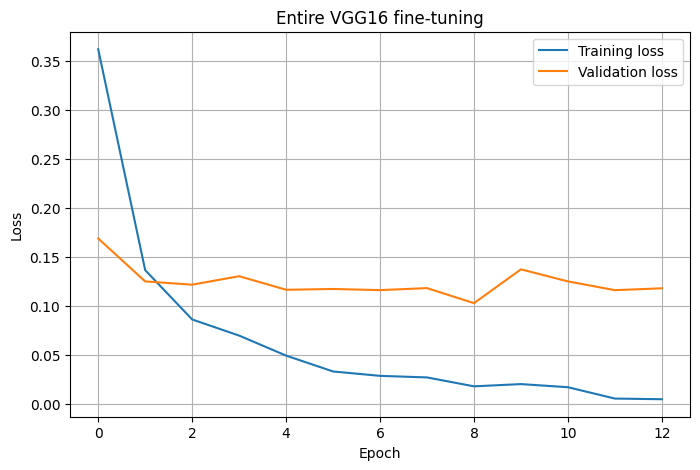

In [4]:
# A) Fine-tune the entire pre-trained VGG16 model
base_model_full = VGG16(
    include_top=False,
    weights="imagenet",
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    pooling="avg"
)
base_model_full.trainable = True

inputs_full = layers.Input(shape=(32, 32, 3))
resized_full = layers.Resizing(IMAGE_SIZE, IMAGE_SIZE)(inputs_full)
augmented_full = layers.RandomFlip("horizontal")(resized_full)
augmented_full = layers.RandomRotation(0.05)(augmented_full)
processed_full = layers.Lambda(preprocess_input)(augmented_full)
features_full = base_model_full(processed_full)
outputs_full = layers.Dense(3, activation="softmax")(features_full)
full_model = Model(inputs_full, outputs_full)

full_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

full_callbacks = [
    EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7, verbose=1)
]

history_full = full_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=full_callbacks,
    verbose=1
)

full_test_loss, full_test_accuracy = full_model.evaluate(test_dataset, verbose=0)
print("Entire VGG16 fine-tuning test accuracy:", full_test_accuracy)

plt.figure(figsize=(8, 5))
plt.plot(history_full.history["loss"], label="Training loss")
plt.plot(history_full.history["val_loss"], label="Validation loss")
plt.title("Entire VGG16 fine-tuning")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 52ms/step - accuracy: 0.8511 - loss: 0.5616 - val_accuracy: 0.9270 - val_loss: 0.2262 - learning_rate: 1.0000e-05
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 51ms/step - accuracy: 0.9254 - loss: 0.2114 - val_accuracy: 0.9437 - val_loss: 0.1829 - learning_rate: 1.0000e-05
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 52ms/step - accuracy: 0.9504 - loss: 0.1399 - val_accuracy: 0.9520 - val_loss: 0.1608 - learning_rate: 1.0000e-05
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 52ms/step - accuracy: 0.9611 - loss: 0.1091 - val_accuracy: 0.9533 - val_loss: 0.1401 - learning_rate: 1.0000e-05
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 51ms/step - accuracy: 0.9689 - loss: 0.0890 - val_accuracy: 0.9580 - val_loss: 0.1441 - learning_rate: 1.0000e-05
Epoch 6/20
374/375 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.9772 - loss: 0.0639
Epoch 6: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 52ms/step - a

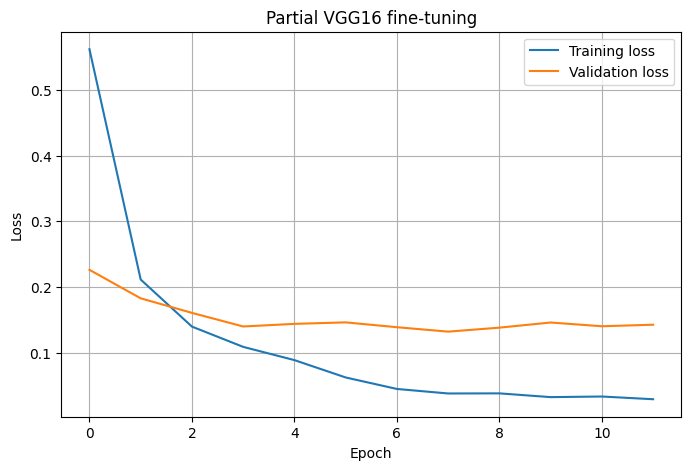

In [5]:
# B) Partially fine-tune VGG16: freeze blocks 1-4 and train block 5
base_model_partial = VGG16(
    include_top=False,
    weights="imagenet",
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    pooling="avg"
)

base_model_partial.trainable = True
for layer in base_model_partial.layers:
    layer.trainable = layer.name.startswith("block5_")

inputs_partial = layers.Input(shape=(32, 32, 3))
resized_partial = layers.Resizing(IMAGE_SIZE, IMAGE_SIZE)(inputs_partial)
augmented_partial = layers.RandomFlip("horizontal")(resized_partial)
augmented_partial = layers.RandomRotation(0.05)(augmented_partial)
processed_partial = layers.Lambda(preprocess_input)(augmented_partial)
features_partial = base_model_partial(processed_partial)
outputs_partial = layers.Dense(3, activation="softmax")(features_partial)
partial_model = Model(inputs_partial, outputs_partial)

partial_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

partial_callbacks = [
    EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7, verbose=1)
]

history_partial = partial_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=partial_callbacks,
    verbose=1
)

partial_test_loss, partial_test_accuracy = partial_model.evaluate(test_dataset, verbose=0)
print("Partial VGG16 fine-tuning test accuracy:", partial_test_accuracy)

plt.figure(figsize=(8, 5))
plt.plot(history_partial.history["loss"], label="Training loss")
plt.plot(history_partial.history["val_loss"], label="Validation loss")
plt.title("Partial VGG16 fine-tuning")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

Test accuracy comparison
Entire VGG16 fine-tuning: 0.968666672706604
Partial VGG16 fine-tuning: 0.9546666741371155


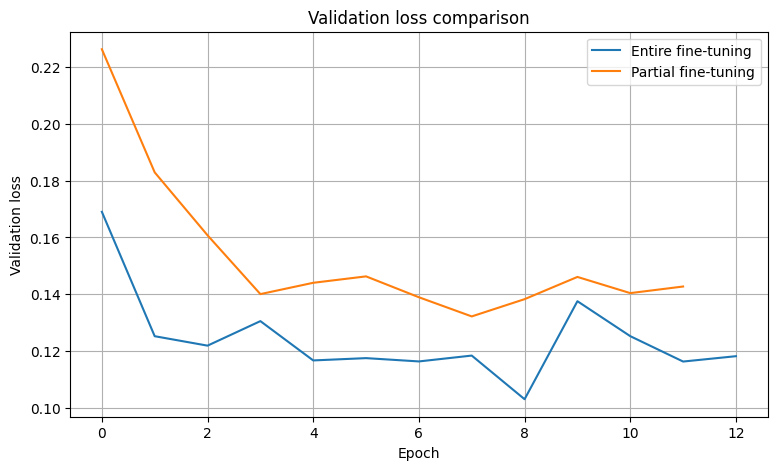

In [6]:
# Compare the effect of full and partial fine-tuning
print("Test accuracy comparison")
print("Entire VGG16 fine-tuning:", full_test_accuracy)
print("Partial VGG16 fine-tuning:", partial_test_accuracy)

plt.figure(figsize=(9, 5))
plt.plot(history_full.history["val_loss"], label="Entire fine-tuning")
plt.plot(history_partial.history["val_loss"], label="Partial fine-tuning")
plt.title("Validation loss comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.legend()
plt.grid(True)
plt.show()

Test accuracy comparison
Entire VGG16 fine-tuning:  0.9687
Partial VGG16 fine-tuning: 0.9547


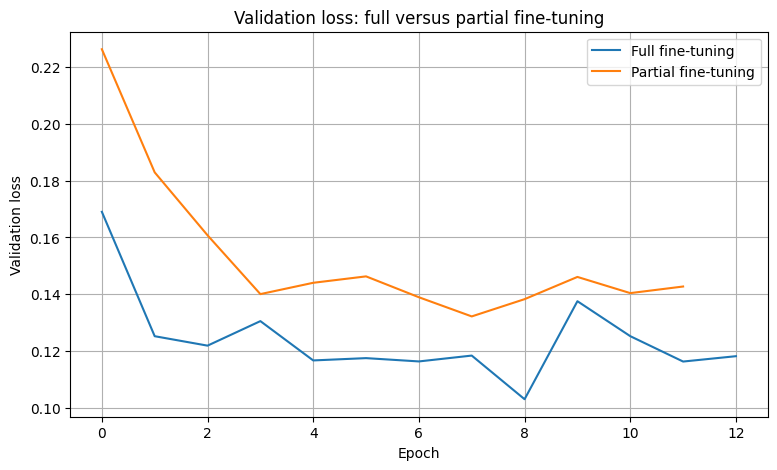

In [7]:
# Compare the effect of the two fine-tuning strategies
print("Test accuracy comparison")
print(f"Entire VGG16 fine-tuning:  {full_test_accuracy:.4f}")
print(f"Partial VGG16 fine-tuning: {partial_test_accuracy:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(history_full.history["val_loss"], label="Full fine-tuning")
plt.plot(history_partial.history["val_loss"], label="Partial fine-tuning")
plt.title("Validation loss: full versus partial fine-tuning")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.legend()
plt.grid(True)
plt.show()